In [1]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

from simsopt.mhd import Vmec

from spectre import SPECTRE, SPECTREout, vmec2spectre

%load_ext autoreload
%autoreload 2

%matplotlib ipympl

 - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - -
  VMEC OUTPUT FILES ALREADY EXIST: OVERWRITING THEM ...
  SEQ =    1 TIME SLICE  0.0000E+00
  PROCESSING INPUT.iota
  THIS IS PARVMEC (PARALLEL VMEC), VERSION 9.0
  Lambda: Full Radial Mesh. L-Force: hybrid full/half.

  COMPUTER: x86_64-conda-linux-gnu   OS: linux   RELEASE: x86_64  DATE = Mar 04,2026  TIME = 12:29:01


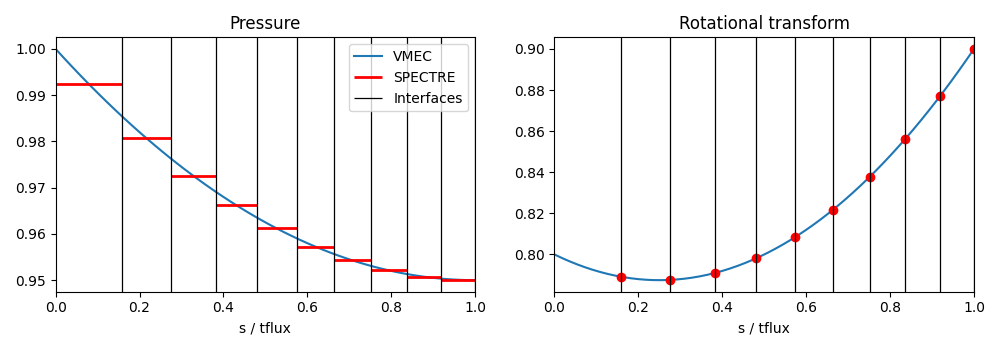

In [4]:
vmec_obj_in = Vmec('input.iota')
vmec_obj_out = Vmec('wout_iota.nc')

# Interfaces parametrized in tflux (free parameter)
tfluxes = np.linspace(0, 1., 11, endpoint=True)[1:]**.8

dict_total = vmec2spectre(vmec_obj_in, tfluxes=tfluxes, plot=True, current_mode='sheet', filename='gen_init.toml')

In [14]:
# Now to start with a good interface guess, the following script based on map2disc can be used

! source ~/src_spectre.sh; init_infaces.py gen_init.toml -o gen.toml


CondaError: Run 'conda init' before 'conda activate'

readin :            : 
readin :       1.63 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  0 ; phiedge=  1.381320248746202E+02 ; curtor=  0.000000000000000E+00 ; curpol=  0.000000000000000E+00 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  1 ; Nvol= 10 ; Mvol= 10 ; Mpol=  6 ; Ntor=  5 
readin :            : pscale=  1.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  1 ; mupf: tol,its=  1.00E-14,   8 
readin :            : Lrad = 10,10,10,10,10,10,10,10,10,10,
readin :            : 
readin :       1.63 : Linitialize=  1 ;LautoinitBn=  1 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : Lsparse= 0 ; Lsvdiota= 0 ; imethod= 3 ; iorder= 2 ; iprecon= 0 ; iotatol        = -1.00000E+00 
readin :            : Mregular= -1 ; Lrzaxis= 1 ; Ntoraxis= 3 ; Lvcgrid= 0 
readin :            : 
readin : 

In [15]:
# Now run SPECTRE

! source ~/src_spectre.sh; calc_spectre_field.py gen.toml


CondaError: Run 'conda init' before 'conda activate'

readin :            : 
readin :       2.24 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  0 ; phiedge=  1.381320248746202E+02 ; curtor=  0.000000000000000E+00 ; curpol=  0.000000000000000E+00 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  1 ; Nvol= 10 ; Mvol= 10 ; Mpol=  6 ; Ntor=  5 
readin :            : pscale=  1.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  1 ; mupf: tol,its=  1.00E-14,   8 
readin :            : Lrad = 10,10,10,10,10,10,10,10,10,10,
readin :            : 
readin :       2.24 : Linitialize=  0 ;LautoinitBn=  1 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : Lsparse= 0 ; Lsvdiota= 0 ; imethod= 3 ; iorder= 2 ; iprecon= 0 ; iotatol        = -1.00000E+00 
readin :            : Mregular= -1 ; Lrzaxis= 1 ; Ntoraxis= 3 ; Lvcgrid= 0 
readin :            : 
readin : 

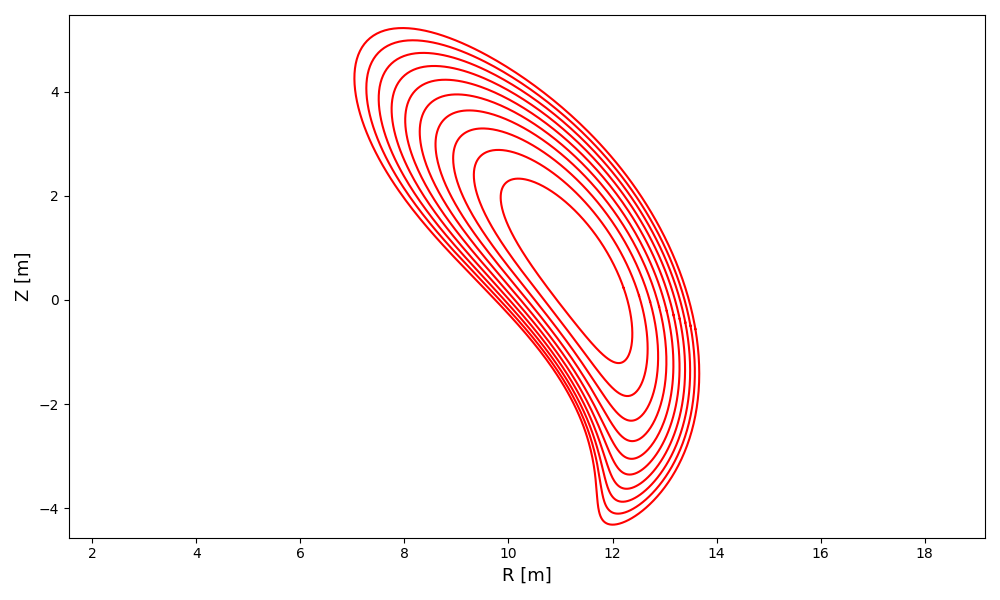

In [23]:
out = SPECTREout('gen.h5')

fig, ax = plt.subplots(figsize=(10, 6))
out.plot_infaces(ax=ax, zetan=0.2)

plt.tight_layout()